Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

In [101]:
import pandas as pd
import matplotlib.pyplot as plt # viz
import seaborn as sns # better viz
import numpy as np # numerical python

%matplotlib inline
pd.set_option('display.max_columns', None)

In [102]:
df = pd.read_csv(r"amz_uk_price_prediction_dataset.csv")

In [103]:
num = df.select_dtypes(include="number")
cat = df.select_dtypes(exclude="number")

In [104]:
cat.columns

Index(['asin', 'title', 'isBestSeller', 'category'], dtype='object')

In [105]:
crosstab_result2 = pd.crosstab(cat['category'], cat['isBestSeller'])
crosstab_result2

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [106]:
proportion_cross2 = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')
proportion_cross2

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


In [107]:
proportion_sort = proportion_cross2.sort_values(by=[True, False],ascending=False)
proportion_sort

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
Snowboard Boots,1.000000,0.000000
Toy Advent Calendars,1.000000,0.000000
USB Gadgets,1.000000,0.000000


In [108]:
proportion_cross = ((crosstab_result2[True]/(crosstab_result2[False]+crosstab_result2[True]))).sort_values(ascending=False)
proportion_cross


category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
                                    ...   
Power Supplies                    0.000000
Ski Helmets                       0.000000
Ski Goggles                       0.000000
Snowboard Boots                   0.000000
eBook Readers & Accessories       0.000000
Length: 296, dtype: float64

**Best-Seller conclusion**

Being a best-seller have 2 arguments True or False were False = 0 and True = 1.
No, as we can conclude is very rare to have categories where being a best-seller is more prevalent! Even when we have the proportion is very small, the highest proportion is 0.058.

2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [109]:
from scipy.stats import chi2_contingency

In [110]:
crosstab_result2

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [111]:
_, chi2_pvalue, _, _  =chi2_contingency(crosstab_result2)
chi2_pvalue

np.float64(0.0)

In [112]:
if chi2_pvalue <=0.05:
    print("this suggests that there is a significant association between the categorical variables. ")

else:
    print("This indicates that there is not enough evidence to conclude a significant association between the variables.")

this suggests that there is a significant association between the categorical variables. 


3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart. (top 10 of proportion table)

In [113]:
proportion_sort2 = proportion_sort.head(10)
proportion_sort2

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Mirrors,0.972000,0.028000


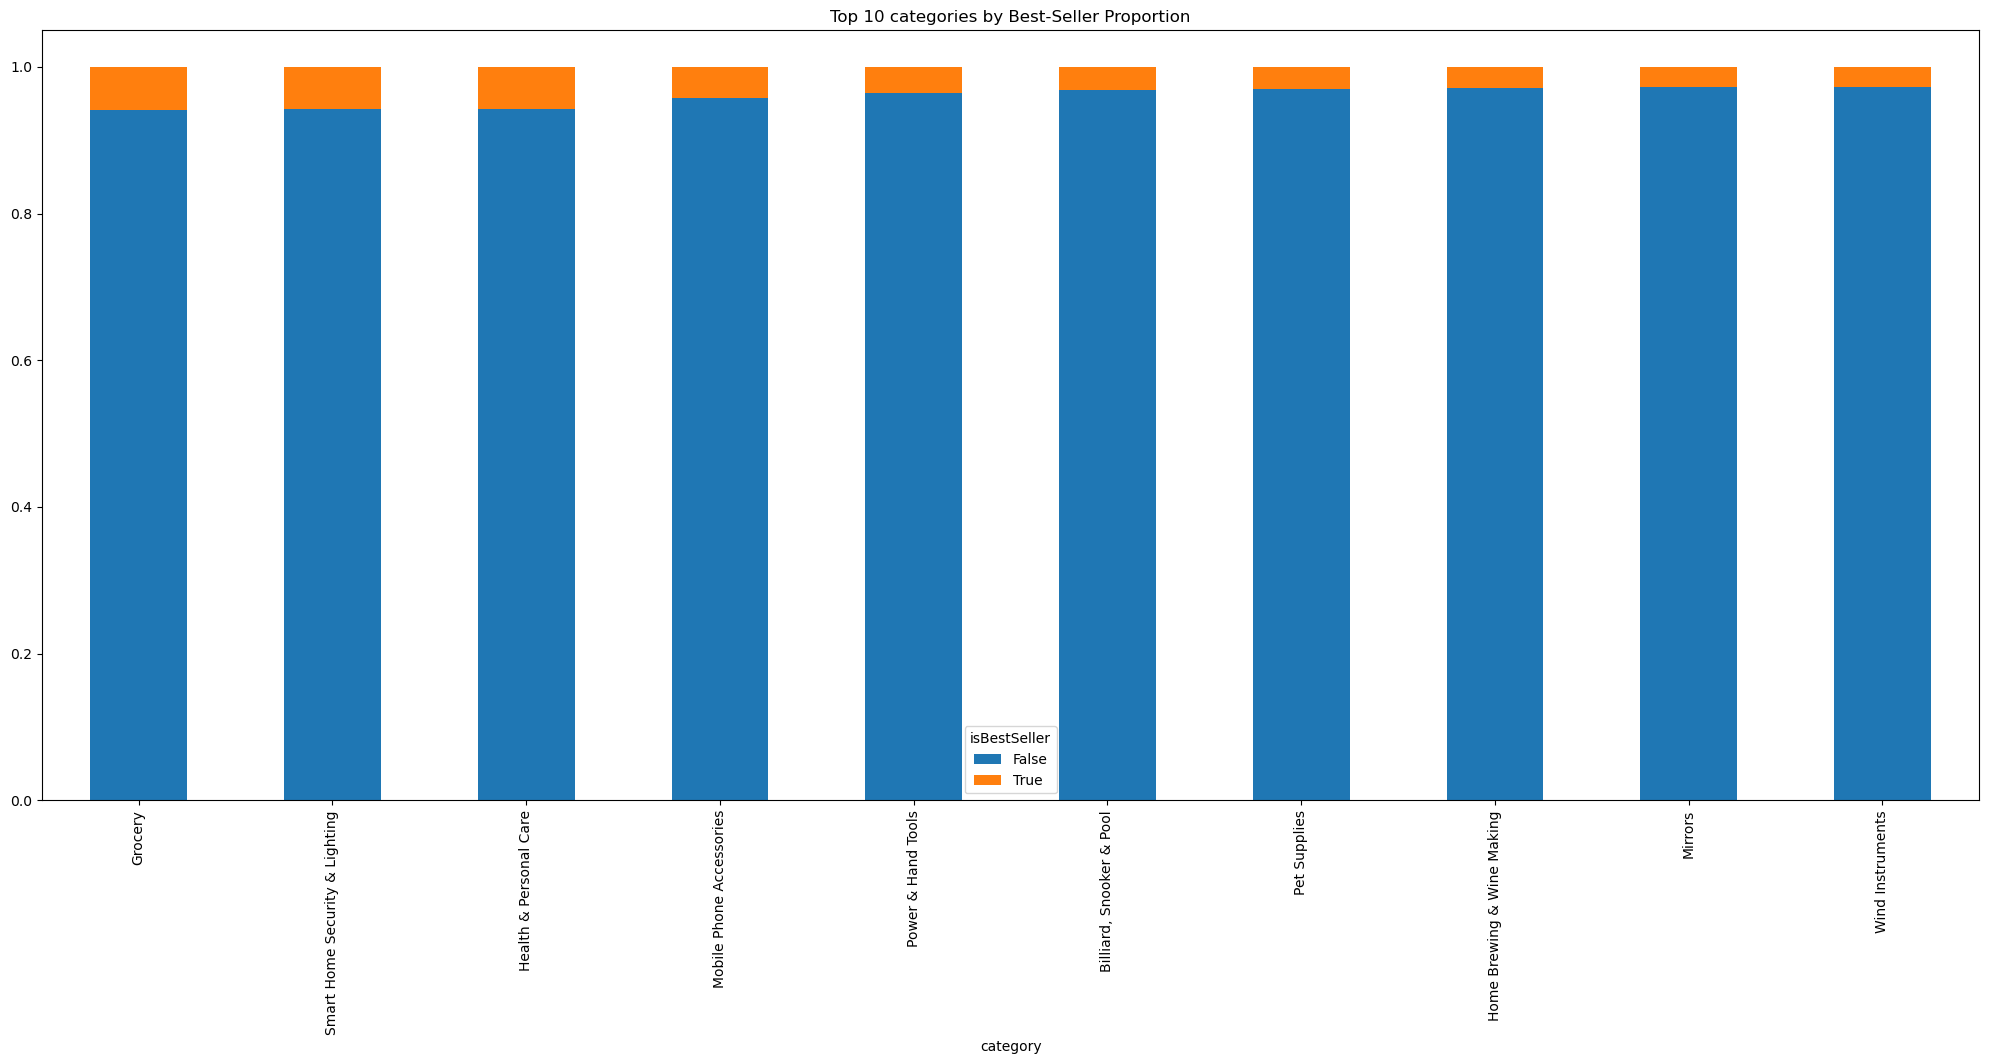

In [114]:
proportion_sort2.plot(kind='bar', stacked=True, figsize=(25,10))
plt.title("Top 10 categories by Best-Seller Proportion")
plt.show()

**Conclusion of top 10 best-seller categories**

- We can conclude that our top 10 categories have a very small proportion of being a best seller even if they are the top 10, still the proportion is very low. 

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

In [152]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [153]:
round(df["price"].describe(),2)

count    2443651.00
mean          89.24
std          345.61
min            0.00
25%            9.99
50%           19.09
75%           45.99
max       100000.00
Name: price, dtype: float64

In [154]:
Q1 = np.percentile(df["price"],25)
Q1

np.float64(9.99)

In [155]:
Q1 = 9.99
Q2 = 19.09
Q3 = 45.99

In [156]:
C = 1.5
IIQ = Q3 - Q1
LI = Q1 - (C*IIQ)
LS = Q3 + (C*IIQ)

print("IIQ is:", IIQ)
print("LI is: ", LI)
print(f"LS is: , {LS:.2f}")

IIQ is: 36.0
LI is:  -44.01
LS is: , 99.99


In [158]:
df_no_outliers = df[(df["price"]>= LI) & (df["price"]<= LS)]

print(f"with outliers: {len(df)}")
print(f"without outliers: {len(df_no_outliers)}")

with outliers: 2443651
without outliers: 2115963


In [159]:
df_no_outliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories. (no visualization question, so use filter for top categories)

In [160]:
#list for the subset
top_20 = df_no_outliers["category"].value_counts().nlargest(20).index
top_20

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts', 'Handmade Home Décor',
       'Luggage and travel gear', 'Women', 'Fragrances',
       'Handmade Kitchen & Dining', 'Handmade Artwork',
       'Handmade Home & Kitchen Products', 'Handmade Jewellery', 'Men',
       'Baby'],
      dtype='object', name='category')

In [161]:
# subset
df_top_20 = df_no_outliers[df_no_outliers["category"].isin(top_20)]
df_top_20

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
19513,21072,B09477KHQ3,"Personalised Birthday Print Gift ""THE YEAR YOU...",4.5,763,7.99,False,900,Handmade Home & Kitchen Products
19514,21073,B0BSRFQYG8,Wax Melts 4 Bars | Build Your Own Box (Choose ...,3.9,117,6.49,True,800,Handmade Home & Kitchen Products
19515,21074,B09N9GVHV9,"Personalised Birthday Print Gift ""ON THE DAY/Y...",4.6,1155,8.99,True,600,Handmade Home & Kitchen Products
19516,21075,B0BRYGV7PQ,Fresh Wax Melts - Laundry Type Wax Melts - Str...,4.5,56,4.99,True,500,Handmade Home & Kitchen Products
19517,21076,B0B1JHB28R,Manta Makes Work Leaving Gifts | I Used to Wor...,4.7,261,9.95,True,400,Handmade Home & Kitchen Products
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


C:\Users\djeny\AppData\Local\Temp\ipykernel_39716\280834057.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top_20, x="price", y="category", palette="coolwarm")


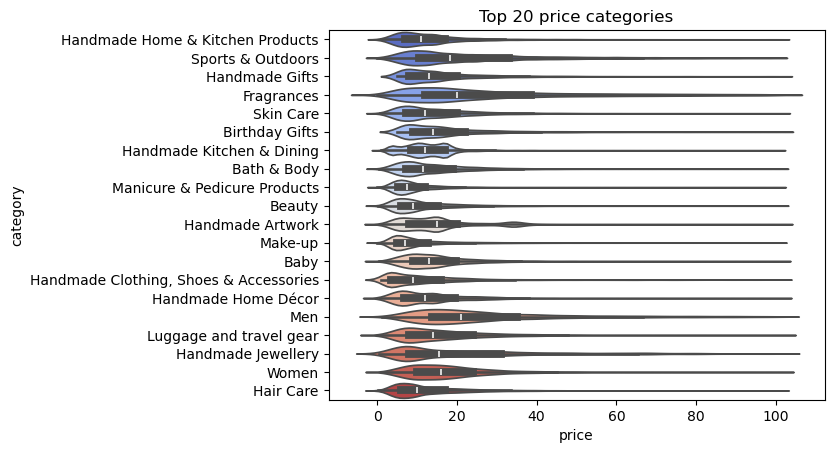

In [162]:
sns.violinplot(data=df_top_20, x="price", y="category", palette="coolwarm")
plt.title("Top 20 price categories")
plt.show()


**Conclusion of the top 20 categories by the price**

- Most part of categories have the fat part of the violin, between 0 and 20, this means that categories items have cheap price!

- All categories have similar max prices and we have Men, Fragrancies and Sports & Outdoors categories that the median is significantly higher, meaning the typical value in this group is more expensive.

- Most part of the categories have a skewed distribution of the prices, with a long thin neck pointing upwards. 

In [164]:
high_med_price2 = df.groupby("category")["price"].median().sort_values(ascending=False)
high_med_price2

category
Laptops                      1042.725
Desktop PCs                   810.400
Snowboards                    366.725
Home Audio Record Players     326.080
3D Printers                   319.000
                               ...   
Adapters                        7.050
Make-up                         7.000
Signs & Plaques                 6.990
Arts & Crafts                   5.990
Office Paper Products           4.380
Name: price, Length: 296, dtype: float64

In [165]:
high_med_price = df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False)
high_med_price

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

**Conclusion median price**

- The product category that have the highest median price is Laptops category with 1042.725 median price with outliers and Desktop PCs with 74 median price without outliers.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

In [166]:
df_no_outliers["category"].value_counts()

category
Sports & Outdoors                         694092
Beauty                                     19233
Bath & Body                                19050
Manicure & Pedicure Products               18904
Handmade Clothing, Shoes & Accessories     18811
                                           ...  
Home Entertainment                            57
Smart Speakers                                49
Alexa Built-In Devices                        39
3D Printers                                   36
Motorbike Exhaust & Exhaust Systems           28
Name: count, Length: 296, dtype: int64

In [167]:
#list for the subset
top_10 = df_no_outliers["category"].value_counts().nlargest(10).index
top_10

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='object', name='category')

In [183]:
#subset
df_top = df_no_outliers[df_no_outliers["category"].isin(top_10)]
df_top

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
82163,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
82164,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
82167,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
82168,89488,B07QDMLMJH,Nextbase Powered Mount Variations For Cameras ...,4.7,1223,19.95,False,0,Sports & Outdoors
82169,89489,B09TQMCNY7,WOLFANG Action Camera GA100 with 64GB microSDX...,4.2,55,49.99,False,0,Sports & Outdoors
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


C:\Users\djeny\AppData\Local\Temp\ipykernel_39716\4152104054.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = df_top, x="category", y="price",palette="Paired", legend=True)


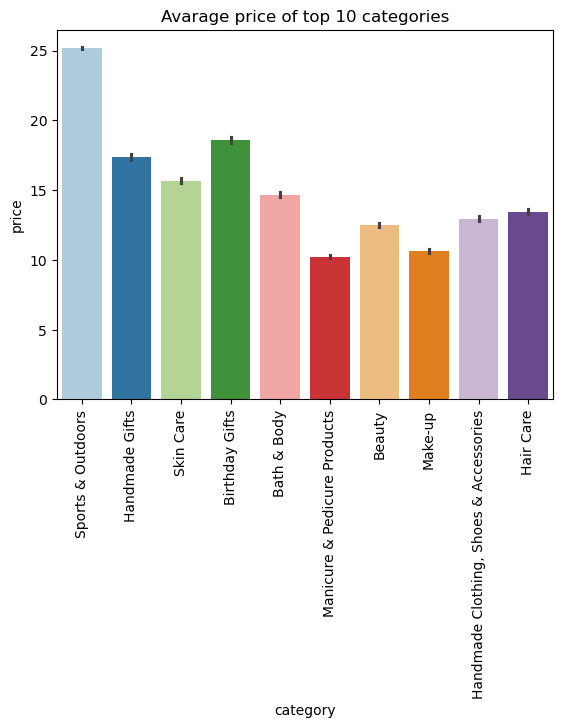

In [184]:
sns.barplot(data = df_top, x="category", y="price",palette="Paired", legend=True)
plt.title("Avarage price of top 10 categories")
plt.xticks(rotation = 90)
plt.show()

**Conclusion of Avarage price**

- The category with the highest Avarage price is Sport & Outdoors with around 25 Avarage price and the category with the lowest Avarage price category is Manicure & Pedicure Products with around 10 Avarage price.
- From the error bars in the barplot we can conclude that the 2 category that have a error bar a slightly higher than the other categories are Birthday Gifts and Handmade Gifts, this means we have a price dispersion higher than in the other categories where the error bar is smaller.
- This analysis confirms that category type is a primary driver of price variation in our dataset.

In [188]:
high_mean_price = df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False)
high_mean_price

category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

**Conclusion mean price**

- The category that commands the highest avarage price is Motherboards with 68.77 avarage price.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [132]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [133]:
df["stars"]

0          4.7
1          4.7
2          4.7
3          4.7
4          4.6
          ... 
2443646    0.0
2443647    0.0
2443648    0.0
2443649    4.3
2443650    4.5
Name: stars, Length: 2443651, dtype: float64

In [134]:
round(df["stars"].describe(),2)

count    2443651.00
mean           2.15
std            2.19
min            0.00
25%            0.00
50%            0.00
75%            4.40
max            5.00
Name: stars, dtype: float64

In [135]:
stars_no_00 = df[df["stars"] != 0]
stars_no_00

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443642,2828585,B07DCFQMQL,Speed MaxX BODY ARMOUR CE MOTORBIKE/MOTORCYCLE...,3.6,66,49.99,False,0,Motorbike Clothing
2443643,2828586,B07JM5VQFX,Motorcycle Clothing Suit - Motorbike Suit With...,4.1,5,158.99,False,0,Motorbike Clothing
2443644,2828587,B07X98JLFF,GREAT BIKERS GEAR - Bobber Cafe Brat Style Lea...,3.6,12,14.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [136]:
top_10 = stars_no_00["category"].value_counts().nlargest(10).index
top_10

Index(['Sports & Outdoors', 'Beauty', 'Hair Care', 'Skin Care', 'Women',
       'Bath & Body', 'Luggage and travel gear', 'Make-up', 'Men',
       'Manicure & Pedicure Products'],
      dtype='object', name='category')

In [137]:
df_top_10 = stars_no_00[stars_no_00["category"].isin(top_10)]
df_top_10.head(10)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
82163,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
82164,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
82165,89485,B08G2HBBB6,GoPro HERO9 - Waterproof Sports Camera with Fr...,4.5,5161,199.00,True,0,Sports & Outdoors
82166,89486,B09D15SFMQ,GoPro HERO10 Black - Waterproof Action Camera ...,4.4,2467,249.99,False,0,Sports & Outdoors
82167,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
82168,89488,B07QDMLMJH,Nextbase Powered Mount Variations For Cameras ...,4.7,1223,19.95,False,0,Sports & Outdoors
82169,89489,B09TQMCNY7,WOLFANG Action Camera GA100 with 64GB microSDX...,4.2,55,49.99,False,0,Sports & Outdoors
82170,89490,B0CF3VVTLG,GoPro HERO12 Black - Waterproof Action Camera ...,4.1,41,399.00,False,0,Sports & Outdoors
82171,89491,B01171X0UW,NEEWER 50 in 1 Action Camera Accessory Kit Com...,4.5,54495,32.49,False,0,Sports & Outdoors
82172,89492,B0BNK4Y288,GoPro Dual Battery Charger + 2 Enduro Batterie...,4.7,568,59.99,False,0,Sports & Outdoors


C:\Users\djeny\AppData\Local\Temp\ipykernel_39716\2241899508.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_10, x="category", y="stars", palette="coolwarm", legend=True)


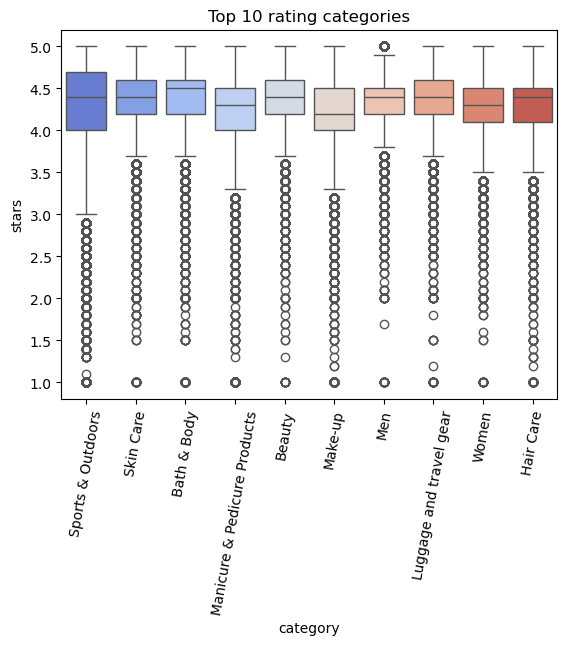

In [138]:
sns.boxplot(data=df_top_10, x="category", y="stars", palette="coolwarm", legend=True)
plt.xticks(rotation = 80)
plt.title("Top 10 rating categories")
plt.show()

**Conclusion distribution top 10 rating categories**

- Overall, all categories have the body between 4 and 5 stars, this means that for the top 10 categories the satisfaction is high even if every category presents significant low-rating outliers, showing that negative experiences occur even in the highest-rated categories.
- Now comparing the categories in this interval between 4 and 5 stars: 
    - Comparing the medians of the categories we can conclude that the category with the highest median rating is Bath & Body category, this show us that the costumers really appreciate this category products, but the same does not happen with the category of Make-up that have the lowest median rating, meaning that the customers does not valorizate that much this category products.
    - Comparing the IQR we can see that the category Sports & Outdoors have the highst variety of satisfaction, due the a large distance between Q1 and Q3 making the box larger. Showing us that the customers does not have consizion about the quality of the products in this category.

In [189]:
high_med_stars = df_no_outliers.groupby("category")["stars"].median().sort_values(ascending=False)
high_med_stars

category
Computer Memory                4.7
Kids' Play Figures             4.6
Beer, Wine & Spirits           4.6
Office Paper Products          4.6
Luxury Food & Drink            4.6
                              ... 
Computer Screws                0.0
Construction Machinery         0.0
Cricket Shoes                  0.0
Curtain & Blind Accessories    0.0
eBook Readers & Accessories    0.0
Name: stars, Length: 296, dtype: float64

**Conclusion median rating**

- The category that tends to receive the highest median ration from the customers is Computer Memory with 4.7 rating.

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?

In [139]:
stars_no_00_1 = df[df["stars"] != 0]
stars_no_00_1

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443642,2828585,B07DCFQMQL,Speed MaxX BODY ARMOUR CE MOTORBIKE/MOTORCYCLE...,3.6,66,49.99,False,0,Motorbike Clothing
2443643,2828586,B07JM5VQFX,Motorcycle Clothing Suit - Motorbike Suit With...,4.1,5,158.99,False,0,Motorbike Clothing
2443644,2828587,B07X98JLFF,GREAT BIKERS GEAR - Bobber Cafe Brat Style Lea...,3.6,12,14.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [140]:
df_ou_00 = df_no_outliers[df_no_outliers["stars"]!=0]
df_ou_00

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443639,2828580,B09GLMT9ML,Scoyco 2pcs Motorcycle Knee Pads Gear Knee Gua...,3.6,25,49.99,False,0,Motorbike Clothing
2443642,2828585,B07DCFQMQL,Speed MaxX BODY ARMOUR CE MOTORBIKE/MOTORCYCLE...,3.6,66,49.99,False,0,Motorbike Clothing
2443644,2828587,B07X98JLFF,GREAT BIKERS GEAR - Bobber Cafe Brat Style Lea...,3.6,12,14.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [141]:
#Spearman method
round(df_ou_00["price"].corr(df_ou_00["stars"], method="spearman"),2)

np.float64(0.02)

In [142]:
#person method
round(float(df_ou_00["price"].corr(df_ou_00["stars"], method="pearson")), 2)

0.01

**Correlation Conclusion**

- As observed, there is no correlation between the variables price and rating as the correlation coeficients are extremely close to 0, spearman = 0,02 and person = 0,01.
- The fact that bouth values are near 0 confirmes that neither a linear and monotonic relationship exists between price and reviews.
- Our last conclusion is that a higher price does not implicate a higher rating and vice-versa.

2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot.

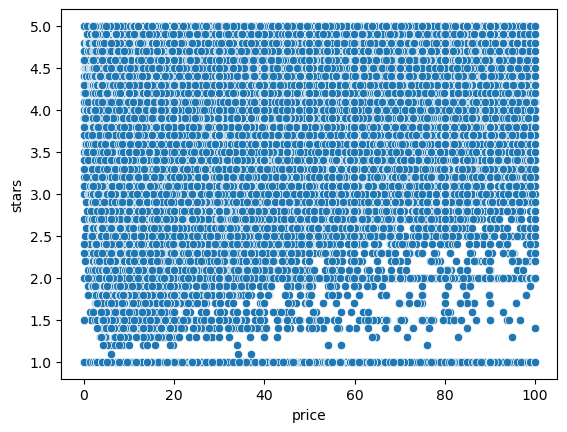

In [143]:
sns.scatterplot(data=df_ou_00, x='price', y='stars')
plt.show()

**Pattern Conclusion**

- The scatter plot show us a random pattern with no clear direction. 
- This confirms our last results regarding correlation coeficient, showing that is no relationship between variable price and ratings. 

In [144]:
num.corr()

,uid,stars,reviews,price,boughtInLastMonth
uid,1.000000,0.031696,0.019994,0.008273,0.016336
stars,0.031696,1.000000,0.085808,-0.124907,0.112536
reviews,0.019994,0.085808,1.000000,-0.013171,0.104043
price,0.008273,-0.124907,-0.013171,1.000000,-0.023439
boughtInLastMonth,0.016336,0.112536,0.104043,-0.023439,1.000000


In [145]:
correlation_matrix = num.corr()
correlation_matrix

,uid,stars,reviews,price,boughtInLastMonth
uid,1.000000,0.031696,0.019994,0.008273,0.016336
stars,0.031696,1.000000,0.085808,-0.124907,0.112536
reviews,0.019994,0.085808,1.000000,-0.013171,0.104043
price,0.008273,-0.124907,-0.013171,1.000000,-0.023439
boughtInLastMonth,0.016336,0.112536,0.104043,-0.023439,1.000000


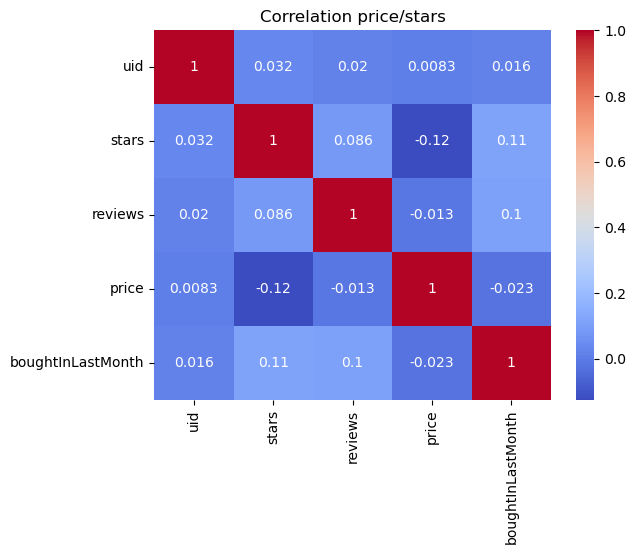

In [146]:
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation price/stars")
plt.show()

**Conclusion Heatmap correlation**

- The heatmap reveals that the strongest positive correlation is between stars and boughtInLastMonth (0.11), while the strongest negative correlation exists between price and stars (-0.12).
- Overall, the correlation coefficients across all numerical variables are negligible, with all values falling between -0.12 and 0.11. This is visually represented by the predominance of neutral colors on the map, indicating that most variables sit very near the zero mark.
- In conclusion, the numerical features in this dataset are statistically independent. This implies that factors such as price do not dictate the volume of recent purchases or the customer satisfaction ratings in a predictable linear way.

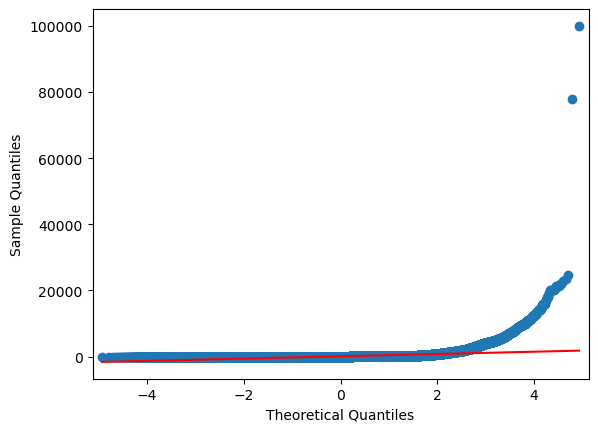

In [191]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'SalePrice' to check if its distribution follows a normal distribution
sm.qqplot(df['price'], line='s');
plt.show()

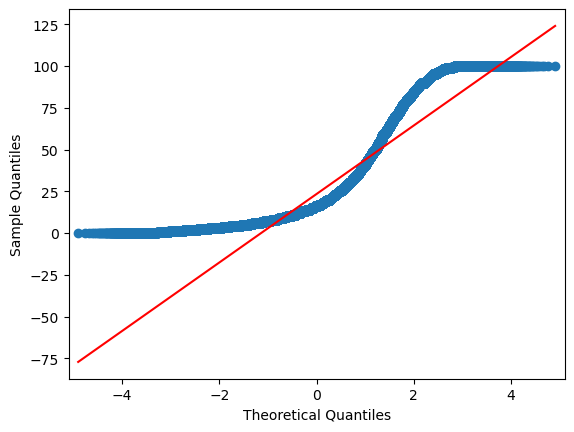

In [147]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'SalePrice' to check if its distribution follows a normal distribution
sm.qqplot(df_no_outliers['price'], line='s');
plt.show()


**Conclusion prices distribution**

- As observed, the price distribution cannot be normal because our data is naturally bounded at zero. While the theoretical normal line (red) extends to negative values (down to -75), our real data remains constant at zero before rising, which causes the first 'flat' section of the S-curve.
- After removing outliers, the data distribution becomes constant again as it approaches 100. Instead of following the red line upwards to infinity, the sample quantiles 'plateau' at the top, confirming that our data is limited and lacks the upper tail of a normal distribution.
- The S-shaped pattern (with points above the line on the left and below on the right) proves a light-tailed distribution. This confirms that our price variable is non-normal and constrained within a specific range.